# Episode 5: Calculus for Learning
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/notebooks/Episode%2005%20-%20Calculus%20for%20Learning.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*.

This notebook reproduces the Math Lab numbers from Episode 5, one step per section. It uses only `numpy` (already installed in Colab), so choose **Runtime, Run all** and nothing else is needed.

Covers: the calculus chain rule on the running example, the nudge, the gradient of a two-variable bowl, the small-step parabola, and the angle between the gradient and the direction to the bottom. The probabilities are the illustrative Episode 1 values. Here **z is the score for “mat”** and **−ln p is called surprisal**, as in the episode.

Every value that appears in the episode is checked with an `assert`. If a cell fails, a number in the script and the math have drifted apart.

## Setup
S(z) = f(g(z)), where f(p) = −ln p and g(z) = e^z / (e^z + R). R = 0.70 is the weight of the other candidates, held fixed.

In [1]:
import numpy as np

R = 0.20 + 0.15 + 0.35                    # weight of the other candidates = 0.70
g = lambda z: np.exp(z) / (np.exp(z) + R)  # probability of "mat" as a function of its score z
f = lambda p: -np.log(p)                   # surprisal
S = lambda z: f(g(z))

z0 = np.log(0.30)
print("R =", R, "  g(z0) =", round(g(z0), 3), "  S(z0) =", round(S(z0), 3), "nats")
assert np.isclose(R, 0.70) and np.isclose(g(z0), 0.30)
assert round(S(z0), 3) == 1.204

R = 0.7   g(z0) = 0.3   S(z0) = 1.204 nats


## Steps 2 to 4: the two links, then the calculus chain rule

In [2]:
p0 = g(z0)
f_prime = -1 / p0                 # f'(p) = -1/p
g_prime = p0 * (1 - p0)           # g'(z) = g(1-g)  (quotient rule; equals R e^z / (e^z + R)^2)
assert np.isclose(g_prime, R * np.exp(z0) / (np.exp(z0) + R) ** 2)

dS_dz = f_prime * g_prime         # calculus chain rule
print("f'(g) =", round(f_prime, 3), "  g'(z) =", round(g_prime, 3), "  dS/dz =", round(dS_dz, 3))
assert np.isclose(dS_dz, -0.70)

# Finite-difference check
eps = 1e-6
fd = (S(z0 + eps) - S(z0 - eps)) / (2 * eps)
print("finite difference:", round(fd, 6))
assert np.isclose(fd, dS_dz, atol=1e-6)

f'(g) = -3.333   g'(z) = 0.21   dS/dz = -0.7
finite difference: -0.7


## Step 5: the nudge
Raise z by 0.10, then by 1.0. The straight-line estimate works for the small step and fails for the large one.

In [3]:
for dz in (0.10, 1.0):
    new_p = g(z0 + dz)
    true_change = S(z0 + dz) - S(z0)
    estimate = dz * dS_dz
    print(f"dz = {dz:4.2f}: p {p0:.3f} -> {new_p:.3f}   surprisal {S(z0):.3f} -> {S(z0+dz):.3f}   true change {true_change:+.3f}   first-order estimate {estimate:+.3f}")

assert round(g(z0 + 0.10), 3) == 0.321
assert round(S(z0 + 0.10), 3) == 1.135
assert round(S(z0 + 0.10) - S(z0), 3) == -0.069
assert round(0.10 * dS_dz, 3) == -0.070
assert round(S(z0 + 1.0) - S(z0), 3) == -0.584

dz = 0.10: p 0.300 -> 0.321   surprisal 1.204 -> 1.135   true change -0.069   first-order estimate -0.070
dz = 1.00: p 0.300 -> 0.538   surprisal 1.204 -> 0.620   true change -0.584   first-order estimate -0.700


**Note from the episode:** you cannot nudge one probability by itself. Under softmax the others must move so the total stays 1. The knob is the score. The same calculation for all four candidates gives a gradient of **p − e**, where e marks the chosen token. This is a first look at the backward pass in Episode 12 (extra check, not shown in the episode script).

In [4]:
p4 = np.array([0.30, 0.20, 0.15, 0.35])
h4 = np.log(p4)
chosen = 0                                   # "mat"

def softmax(h):
    e = np.exp(h - h.max()); return e / e.sum()

def surprisal_of_chosen(h):
    return -np.log(softmax(h)[chosen])

grad = np.zeros(4)
for i in range(4):
    d = np.zeros(4); d[i] = 1e-6
    grad[i] = (surprisal_of_chosen(h4 + d) - surprisal_of_chosen(h4 - d)) / 2e-6

onehot = np.eye(4)[chosen]
print("numerical gradient:", np.round(grad, 4))
print("p - e             :", np.round(p4 - onehot, 4), "  (sums to", round((p4 - onehot).sum(), 12), ")")
assert np.allclose(grad, p4 - onehot, atol=1e-6)
assert np.isclose((p4 - onehot).sum(), 0)

numerical gradient: [-0.7   0.2   0.15  0.35]
p - e             : [-0.7   0.2   0.15  0.35]   (sums to 0.0 )


## The bowl: gradient of a two-variable function
f(z₁, z₂) = z₁² + 2z₂². Then ∇f = (2z₁, 4z₂). At (1, 1), f = 3 and ∇f = (2, 4).

In [5]:
F = lambda z: z[0] ** 2 + 2 * z[1] ** 2
gradF = lambda z: np.array([2 * z[0], 4 * z[1]])

z = np.array([1.0, 1.0])
print("f(1,1) =", F(z), "  gradient =", gradF(z), "  (grad.grad =", gradF(z) @ gradF(z), ")")
assert F(z) == 3 and np.allclose(gradF(z), [2, 4]) and gradF(z) @ gradF(z) == 20

# Check the gradient numerically
fd_grad = np.array([(F(z + e) - F(z - e)) / 2e-6 for e in (np.array([1e-6, 0]), np.array([0, 1e-6]))])
assert np.allclose(fd_grad, gradF(z), atol=1e-5)

f(1,1) = 3.0   gradient = [2. 4.]   (grad.grad = 20.0 )


## Why a small step works, and why “small” matters
Move against the gradient: f(z − η∇f). Computed directly, not from the formula. For this quadratic, f(η) = 3 − 20η + 36η².

In [6]:
def f_of_eta(eta):
    return F(z - eta * gradF(z))

for eta in (0.1, 1.0):
    print(f"eta = {eta}: f = {f_of_eta(eta):.2f}")
assert np.isclose(f_of_eta(0.1), 1.36)
assert np.isclose(f_of_eta(1.0), 19.0)

# The formula matches the direct calculation
for eta in (0.0, 0.05, 0.1, 0.278, 0.5, 1.0):
    assert np.isclose(f_of_eta(eta), 3 - 20 * eta + 36 * eta ** 2)

threshold = 40 / 72          # f falls for every eta between 0 and this
best = 20 / 72               # best step
print(f"f falls for 0 < eta < {threshold:.3f}; best step eta = {best:.3f} gives f = {f_of_eta(best):.3f}")
assert round(threshold, 3) == 0.556 and round(best, 3) == 0.278 and round(f_of_eta(best), 3) == 0.222

# Scan to confirm the threshold and the minimum numerically
etas = np.linspace(0.0, 1.0, 100001)
vals = np.array([3 - 20 * e + 36 * e ** 2 for e in etas])
assert abs(etas[np.argmin(vals)] - best) < 1e-4
assert abs(etas[np.where(vals < 3)[0].max()] - threshold) < 1e-4

eta = 0.1: f = 1.36
eta = 1.0: f = 19.00
f falls for 0 < eta < 0.556; best step eta = 0.278 gives f = 0.222


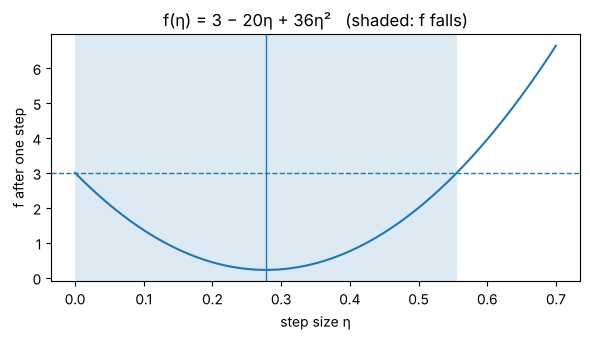

In [7]:
# Optional picture: the parabola f(eta), with the decrease zone shaded
try:
    import matplotlib.pyplot as plt
    x = np.linspace(0, 0.7, 300)
    plt.figure(figsize=(6, 3.5))
    plt.plot(x, 3 - 20 * x + 36 * x ** 2)
    plt.axhline(3, linestyle="--", linewidth=1)
    plt.axvspan(0, threshold, alpha=0.15)
    plt.axvline(best, linewidth=1)
    plt.xlabel("step size η"); plt.ylabel("f after one step")
    plt.title("f(η) = 3 − 20η + 36η²   (shaded: f falls)")
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not available; skipping the picture.")

## Myth check: the gradient does not point to the bottom
At (1, 1), −∇f = (−2, −4) points away from the bottom at (0, 0).

In [8]:
a = -gradF(z)
b = np.array([0.0, 0.0]) - z
angle = np.degrees(np.arccos((a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))))
print(f"angle between -grad f and the direction to the bottom: {angle:.1f} degrees")
assert round(angle, 1) == 18.4

angle between -grad f and the direction to the bottom: 18.4 degrees


## Check question
For f(z₁, z₂) = z₁² + 2z₂² at (2, 1): (a) ∇f? (b) Which unit direction decreases f fastest? (c) About how much does f fall per unit distance that way?

In [9]:
zc = np.array([2.0, 1.0])
gc = gradF(zc)
unit_down = -gc / np.linalg.norm(gc)
print("(a) gradient:", gc)
print("(b) steepest-descent unit direction:", np.round(unit_down, 3), "= (-1, -1)/sqrt(2)")
print("(c) slope per unit distance:", round(np.linalg.norm(gc), 2), "= 4*sqrt(2)")
assert np.allclose(gc, [4, 4])
assert np.allclose(unit_down, np.array([-1, -1]) / np.sqrt(2))
assert np.isclose(np.linalg.norm(gc), 4 * np.sqrt(2))

(a) gradient: [4. 4.]
(b) steepest-descent unit direction: [-0.707 -0.707] = (-1, -1)/sqrt(2)
(c) slope per unit distance: 5.66 = 4*sqrt(2)


In [10]:
print("All Episode 5 checks passed.")

All Episode 5 checks passed.
